# DIII-D free-parameter scan: separatrix-density heat maps

DIII-D version of `../ARC/plot_densfp_compare.ipynb`. At a fixed `alpha_crit`,
`C_KBM` and `De_chie_etg` (by default the
`DIIIDSnyder_ESCAPE_1Dscipyinner_neutralscan` scan from
`scan_SCfp_ESCAPE_DIIID.py`), these heat maps show how the solved profiles at
$\psi_N = 0.85$ depend on the two neutral-density free parameters:

- horizontal axis: $n_{FC}(x=0)$
- vertical axis: $n_{CX}(x=0)/n_{FC}(x=0)$
- colour: $n_e$, $T_e$ and $p_e = n_e T_e$ at $\psi_N = 0.85$, one plot each

Scans are laid out as `<scan>/<equil_tag>/neouter<j>_fp<i>/{out_dict,failed}.npy`,
with the solved ESCAPE `state` in `out_dict.npy`. One equilibrium is plotted at a
time (`EQUIL_TAG`). The 1D model reconstructs $n_{CX}$ from the $n_e$ gradient after
the solve, so its solved $n_{CX}(x=0)$ is not $n_{CX}/n_{FC} \cdot n_{FC}(x=0)$; the
`nFC_x0` / `ncx_x0_ratio` free parameters are used as the scan coordinates. The scan
grid is unevenly spaced, so each grid value gets one equal-size cell. Grey cells
have not been solved yet (the scan may still be running, so re-run the notebook to
pick up new points). Runs that wrote `failed.npy` are labelled *failed*.

In [18]:
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
from pathlib import Path

# Layout written by scan_SCfp_ESCAPE_DIIID.py:
#   <scan>/<equil_tag>/neouter<j>_fp<i>/{out_dict,failed}.npy
#   <scan>/<equil_tag>/neouter<j>_fp<i>/ne_and_Te_iter_<k>.npy
SCAN_DIR = Path('outputs/DIIIDSnyder_ESCAPE_1Dscipyinner_neutralscan_fullset')

# Equilibrium (sub-directory of SCAN_DIR) to plot. None auto-picks the one with
# the most solved runs.
EQUIL_TAG = None
# EQUIL_TAG = '125729.03589'

# Slice held fixed while nFC(0) and nCX(0)/nFC(0) vary. None auto-picks the
# (alpha_crit, C_KBM, De_chie_etg) combination with the most solved runs.
FIXED = {'alpha_crit': None, 'C_KBM': None, 'De_chie_etg': None}

# Radial location at which the colour quantities are evaluated
PSI_EVAL = 0.85

# Scan grid from the scan script, so cells that have not run yet still show
# up as empty. Any extra values found on disk are added automatically.
NFC_X0_GRID = np.array([5e14, 5e15, 5e16, 5e17, 5e18])
NCX_RATIO_GRID = np.array([15])

e_C = 1.602176634e-19  # J/eV

In [19]:
import pickle
import sys
from collections import Counter
from numpy.lib import format as npy_format

# out_dict.npy pickles the ESCAPE state, which references src.* classes
ROOT = Path.cwd().parent.parent.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


class _JuliaStub:
    """Stand-in for juliacall.AnyValue: deserializes to None."""
    @classmethod
    def _jl_deserialize(cls, *args):
        return None


class _NoJuliaUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        if module.startswith('juliacall'):
            return _JuliaStub
        return super().find_class(module, name)


def load_npy_dict(fp):
    """np.load(fp, allow_pickle=True).item(), with juliacall objects replaced by None."""
    with open(fp, 'rb') as f:
        version = npy_format.read_magic(f)
        npy_format._read_array_header(f, version)
        return _NoJuliaUnpickler(f).load().item()


def run_dirs(equil_dir):
    """Scan-point directories neouter<j>_fp<i>, in (j, i) order."""
    def key(p):
        j, i = p.name.removeprefix('neouter').split('_fp')
        return int(j), int(i)
    return sorted((p for p in equil_dir.iterdir() if p.is_dir() and p.name.startswith('neouter')), key=key)


def par(d, k):
    return float(d['free_params'][k])

def x0_densities(d):
    """nFC(x=0) and nCX(x=0)/nFC(x=0), from the nFC_x0 / ncx_x0_ratio free parameters.

    The 1D model does not impose nCX(x=0) = ncx_x0_ratio * nFC_x0; it reconstructs
    nCX from the n_e gradient after the solve, so the solved nCX(x=0) is not the
    scan coordinate.
    """
    return par(d, 'nFC_x0'), par(d, 'ncx_x0_ratio')

def solved_ne_Te(s):
    """(psi_ne, n_e [m^-3], psi_Te, T_e [keV]), each sorted in psi, from the solved state."""
    psi_ne, ne, psi_Te, Te = (np.asarray(s[k], float) for k in ('psi_ne_eval', 'n_e', 'psi_Te_eval', 'T_e'))
    o, p = np.argsort(psi_ne), np.argsort(psi_Te)
    return psi_ne[o], ne[o], psi_Te[p], Te[p]

def values_at_psi(d, psi):
    """ne [10^20 m^-3], Te [keV], p_e = ne*Te [kPa] at psi_N = psi."""
    psi_ne, ne, psi_Te, Te = solved_ne_Te(d['state'])
    ne = float(np.interp(psi, psi_ne, ne))
    Te = float(np.interp(psi, psi_Te, Te))
    return {'ne': ne / 1e20, 'Te': Te, 'p': ne * Te * 1e3 * e_C / 1e3}

def load_scan(equil_dir):
    """(solved runs, failed runs) of one equilibrium."""
    runs, failed = [], []
    for rd in run_dirs(equil_dir):
        if (rd / 'out_dict.npy').exists():
            d = load_npy_dict(rd / 'out_dict.npy')
            (failed if d.get('failed') else runs).append(d)
        if (rd / 'failed.npy').exists():
            failed.append(load_npy_dict(rd / 'failed.npy'))
    return runs, failed

equil_dirs = sorted(p for p in SCAN_DIR.iterdir() if p.is_dir() and any(p.glob('neouter*_fp*')))
if not equil_dirs:
    raise RuntimeError(f'No equilibrium directories with scan points found under {SCAN_DIR}')
scans = {p.name: load_scan(p) for p in equil_dirs}
for tag, (r, f) in scans.items():
    print(f'{tag}: {len(r)} solved, {len(f)} failed')

if EQUIL_TAG is None:
    EQUIL_TAG = max(scans, key=lambda t: len(scans[t][0]))
runs, failed = scans[EQUIL_TAG]

if not runs:
    raise RuntimeError(f'No completed runs with out_dict.npy found under {SCAN_DIR / EQUIL_TAG}')

# Resolve unset fixed values to the slice with the most solved runs
if any(v is None for v in FIXED.values()):
    best = Counter(tuple(par(r, k) for k in FIXED) for r in runs).most_common(1)[0][0]
    FIXED = {k: (v if v is not None else b) for (k, v), b in zip(FIXED.items(), best)}

def in_slice(d):
    return all(np.isclose(par(d, k), v) for k, v in FIXED.items())

slice_runs = [r for r in runs if in_slice(r)]
slice_failed = [f for f in failed if in_slice(f)]

print(f'\nPlotting equilibrium {EQUIL_TAG}')
print('Holding fixed: ' + ',  '.join(f'{k} = {v:.4g}' for k, v in FIXED.items()))
print(f'{len(slice_runs)} solved, {len(slice_failed)} failed in this slice '
      f'({len(NFC_X0_GRID) * len(NCX_RATIO_GRID)} in the scan grid)')

125729.03589: 5 solved, 10 failed
125730.02445: 5 solved, 10 failed
125731.02893: 5 solved, 10 failed
125732.03508: 5 solved, 10 failed
125761.03760: 5 solved, 10 failed
125787.03894: 5 solved, 10 failed
128398.04295: 5 solved, 10 failed
128413.04088: 5 solved, 10 failed
128572.03809: 5 solved, 10 failed
128578.03658: 5 solved, 10 failed
131499.04439: 5 solved, 10 failed
131711.03067: 5 solved, 10 failed
131712.04009: 5 solved, 10 failed
131922.04192: 5 solved, 10 failed
131923.03394: 5 solved, 10 failed
131996.03020: 5 solved, 10 failed
131997.03020: 5 solved, 10 failed
131999.03020: 6 solved, 9 failed
132000.03020: 5 solved, 10 failed
132002.03020: 3 solved, 12 failed
132003.03021: 5 solved, 10 failed
132006.03004: 5 solved, 10 failed
132007.01288: 4 solved, 11 failed
132009.03020: 5 solved, 10 failed
132010.03020: 5 solved, 10 failed
132011.03020: 5 solved, 10 failed
132013.02771: 5 solved, 10 failed
132014.02721: 5 solved, 10 failed
132014.03020: 5 solved, 10 failed
132016.03020: 5

In [20]:
# Fill the (ncx_ratio, nFC) grids. NaN = not solved; failed runs are marked separately.
def _merge(grid, extra):
    vals = list(grid)
    for v in extra:
        if not np.any(np.isclose(vals, v)):
            vals.append(v)
    return np.sort(np.asarray(vals, float))

nFC_vals = _merge(NFC_X0_GRID, [x0_densities(r)[0] for r in slice_runs]
                               + [par(f, 'nFC_x0') for f in slice_failed])
ratio_vals = _merge(NCX_RATIO_GRID, [x0_densities(r)[1] for r in slice_runs]
                                    + [par(f, 'ncx_x0_ratio') for f in slice_failed])

def _idx(vals, v):
    return int(np.argmin(np.abs(np.log(vals) - np.log(v))))

QUANTS = {
    'ne': {'label': rf'$n_e(\psi_N={PSI_EVAL})$ [$10^{{20}}$ m$^{{-3}}$]', 'cmap': 'Blues', 'fmt': '{:.3f}'},
    'Te': {'label': rf'$T_e(\psi_N={PSI_EVAL})$ [keV]',                  'cmap': 'Oranges', 'fmt': '{:.2f}'},
    'p':  {'label': rf'$p_e = n_e T_e\,(\psi_N={PSI_EVAL})$ [kPa]',        'cmap': 'Greens', 'fmt': '{:.1f}'},
}

grids = {k: np.full((len(ratio_vals), len(nFC_vals)), np.nan) for k in QUANTS}
failed_mask = np.zeros((len(ratio_vals), len(nFC_vals)), bool)

for r in slice_runs:
    nFC0, ratio0 = x0_densities(r)
    i, j = _idx(ratio_vals, ratio0), _idx(nFC_vals, nFC0)
    for k, v in values_at_psi(r, PSI_EVAL).items():
        grids[k][i, j] = v
for f in slice_failed:
    failed_mask[_idx(ratio_vals, par(f, 'ncx_x0_ratio')), _idx(nFC_vals, par(f, 'nFC_x0'))] = True

In [21]:
from matplotlib.colors import Normalize

def plot_heatmap(key):
    q = QUANTS[key]
    Z = grids[key]
    cmap = plt.get_cmap(q['cmap']).copy()
    cmap.set_bad('0.92')                 # unsolved / pending cells

    fig, ax = plt.subplots(figsize=(7.5, 5.5))
    finite = Z[np.isfinite(Z)]
    norm = Normalize(finite.min(), finite.max()) if finite.size else Normalize(0, 1)

    # Scan values are unevenly spaced, so draw one equal-size cell per grid value
    # and label the ticks with the actual values.
    im = ax.imshow(np.ma.masked_invalid(Z), origin='lower', aspect='auto',
                   cmap=cmap, norm=norm, interpolation='nearest')

    for i in range(Z.shape[0]):
        for j in range(Z.shape[1]):
            if np.isfinite(Z[i, j]):
                shade = norm(Z[i, j])
                ax.text(j, i, q['fmt'].format(Z[i, j]), ha='center', va='center',
                        fontsize=10, color='white' if shade > 0.6 else 'black')
            elif failed_mask[i, j]:
                ax.text(j, i, 'failed', ha='center', va='center', fontsize=9, color='0.35')

    # Thin surface-coloured gaps between cells
    ax.set_xticks(np.arange(-0.5, Z.shape[1]), minor=True)
    ax.set_yticks(np.arange(-0.5, Z.shape[0]), minor=True)
    ax.grid(which='minor', color='white', lw=2)
    ax.tick_params(which='minor', length=0)

    ax.set_xticks(np.arange(len(nFC_vals)))
    ax.set_xticklabels([f'{v:.2e}' for v in nFC_vals], rotation=30, ha='right')
    ax.set_yticks(np.arange(len(ratio_vals)))
    ax.set_yticklabels([f'{v:g}' for v in ratio_vals])
    ax.tick_params(axis='both', labelsize=12)
    ax.set_xlabel(r'$n_{FC}(x=0)$ [m$^{-3}$]', fontsize=14)
    ax.set_ylabel(r'$n_{CX}(x=0)\,/\,n_{FC}(x=0)$', fontsize=14)
    ax.set_title(rf'{EQUIL_TAG}:  $\alpha_{{crit}}$ = {FIXED["alpha_crit"]:.3g},  '
                 rf'$C_{{KBM}}$ = {FIXED["C_KBM"]:.3g},  '
                 rf'$D_{{ETG}}/\chi_{{e}}$ = {FIXED["De_chie_etg"]:.3g}', fontsize=12)
    for s in ax.spines.values():
        s.set_visible(False)

    cb = fig.colorbar(im, ax=ax)
    cb.set_label(q['label'], fontsize=13)
    cb.ax.tick_params(labelsize=11)
    fig.tight_layout()
    return fig, ax

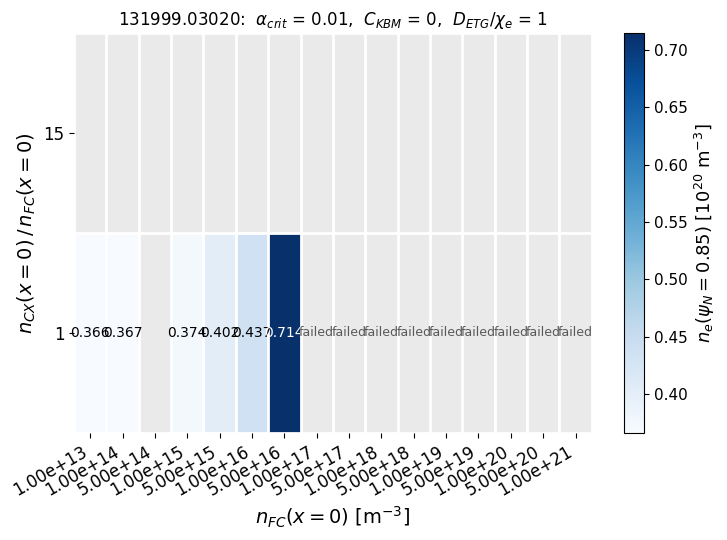

In [22]:
fig, ax = plot_heatmap('ne')
plt.show()

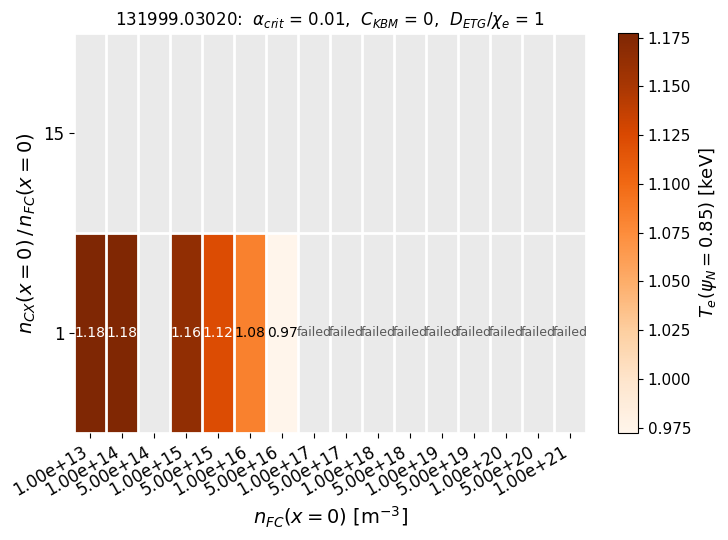

In [23]:
fig, ax = plot_heatmap('Te')
plt.show()

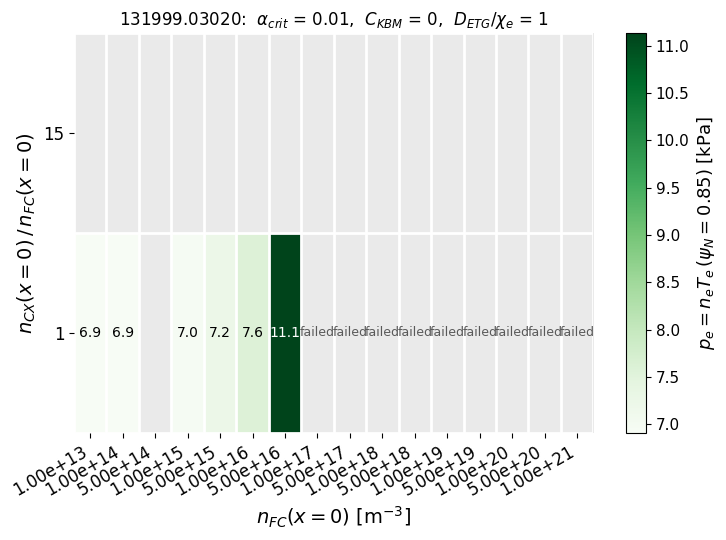

In [24]:
fig, ax = plot_heatmap('p')
plt.show()

## Profiles at $\psi_N = 0.85$ versus separatrix density

The same slice collapsed onto one axis, $n_{FC}(x=0)$ (as in the ARC notebook),
with $n_e$ and $T_e$ on separate y-axes. $p_e$ is in arbitrary units, rescaled
onto the $n_e$ axis (mean matched to the mean of $n_e$) so its trend can be
compared directly. The runs are joined in order of $n_{FC}(x=0)$, so combinations
with equal $n_{FC}(x=0)$ but different $n_{CX}/n_{FC}$ show up as steps.

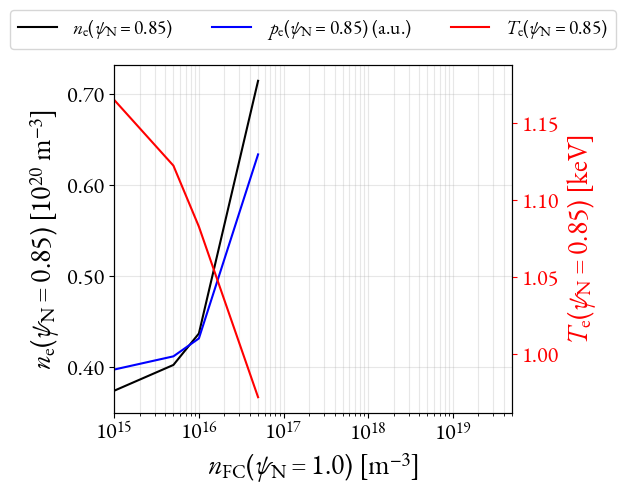

6 runs, values at psi_N = 0.85
    nFC_x0 = 1.00e+13, ratio = 1:  ne = 0.366e20 m^-3, Te = 1.177 keV, pe = 6.91 kPa
    nFC_x0 = 1.00e+14, ratio = 1:  ne = 0.367e20 m^-3, Te = 1.176 keV, pe = 6.92 kPa
    nFC_x0 = 1.00e+15, ratio = 1:  ne = 0.374e20 m^-3, Te = 1.165 keV, pe = 6.97 kPa
    nFC_x0 = 5.00e+15, ratio = 1:  ne = 0.402e20 m^-3, Te = 1.122 keV, pe = 7.23 kPa
    nFC_x0 = 1.00e+16, ratio = 1:  ne = 0.437e20 m^-3, Te = 1.083 keV, pe = 7.57 kPa
    nFC_x0 = 5.00e+16, ratio = 1:  ne = 0.714e20 m^-3, Te = 0.972 keV, pe = 11.13 kPa


In [27]:
from matplotlib import font_manager
from matplotlib.ticker import FormatStrFormatter

def n_sep_x0(r):
    # x-axis: nFC(x=0) (as in the ARC notebook)
    nFC0, ratio0 = x0_densities(r)
    return nFC0

fs = 20

# EB Garamond (OFL, from Google Fonts) for text, ticks and mathtext, this figure only
for f in (Path.home() / '.local/share/fonts/EBGaramond').glob('*.ttf'):
    font_manager.fontManager.addfont(str(f))
GARAMOND_RC = {
    'font.family': 'EB Garamond',
    'mathtext.fontset': 'custom',
    'mathtext.rm': 'EB Garamond',
    'mathtext.it': 'EB Garamond:italic',
    'mathtext.bf': 'EB Garamond:bold',
    'mathtext.cal': 'EB Garamond:italic',
}

sep_runs = sorted(slice_runs, key=n_sep_x0)
nsep = np.array([n_sep_x0(r) for r in sep_runs])
at = [values_at_psi(r, PSI_EVAL) for r in sep_runs]
ne_sep = np.array([v['ne'] for v in at])
Te_sep = np.array([v['Te'] for v in at])
pe_sep = np.array([v['p'] for v in at])

# p_e in arbitrary units, placed on the n_e axis
pe_au = pe_sep * ne_sep.mean() / pe_sep.mean()

with plt.rc_context(GARAMOND_RC):
    fig, ax = plt.subplots(figsize=(6, 5))
    ax2 = ax.twinx()

    ax.plot(nsep, ne_sep, '-', color='k', label=rf'$n_\mathrm{{e}}(\psi_\mathrm{{N}}={PSI_EVAL})$')
    ax.plot(nsep, pe_au, '-', color='b', label=rf'$p_\mathrm{{e}}(\psi_\mathrm{{N}}={PSI_EVAL})$ (a.u.)')
    ax2.plot(nsep, Te_sep, '-', color='r', label=rf'$T_\mathrm{{e}}(\psi_\mathrm{{N}}={PSI_EVAL})$')

    ax.set_xscale('log')
    ax.set_xlabel(r'$n_\mathrm{FC}(\psi_\mathrm{N} = 1.0)$ [m$^{-3}$]', fontsize=fs)
    ax.set_ylabel(rf'$n_\mathrm{{e}}(\psi_\mathrm{{N}}={PSI_EVAL})$ [$10^{{20}}$ m$^{{-3}}$]', fontsize=fs)
    ax2.set_ylabel(rf'$T_\mathrm{{e}}(\psi_\mathrm{{N}}={PSI_EVAL})$ [keV]', color='r', fontsize=fs)
    ax2.tick_params(axis='y', colors='r', labelsize=fs-4)
    ax.tick_params(axis='x', labelsize=fs-4)
    ax.tick_params(axis='y', labelsize=fs-4)
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
    ax2.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

    ax.grid(alpha=0.3, which='both')

    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    fig.legend(h1 + h2, l1 + l2, loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=3, fontsize=fs-6)
    ax.set_xlim(1e15, 5e19)
    ax.set_xticks([1e15, 1e16, 1e17, 1e18, 1e19])
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    fig.savefig(f'densfp_compare_{EQUIL_TAG}_DIIID.png',dpi=600)
    plt.show()

print(f'{len(sep_runs)} runs, values at psi_N = {PSI_EVAL}')
for r, v in zip(sep_runs, at):
    print(f"    nFC_x0 = {par(r, 'nFC_x0'):.2e}, ratio = {par(r, 'ncx_x0_ratio'):g}:  "
          f"ne = {v['ne']:.3f}e20 m^-3, Te = {v['Te']:.3f} keV, pe = {v['p']:.2f} kPa")

## Final ESCAPE profiles at one $n_{FC}(\psi_N = 1)$

Final (converged) $n_e$ and $T_e$ from the solved ESCAPE `state` of the run with
$n_{FC}(x=0) = $ `NFC_PLOT` (solid), against the input experimental profiles
(dotted). Top row: all of $\psi_N \in [0, 1]$; bottom row: zoomed to
$\psi_N \geq$ `PSI_ZOOM`. The SC inner boundary and the ESCAPE pedestal top
($1 - \Delta_{ped}$) are marked.

In [17]:
# Final ESCAPE n_e and T_e profiles of one scan point, against the input profiles
NFC_PLOT = 1e5      # nFC(psi_N = 1) = nFC(x=0) of the run to plot [m^-3]
PSI_ZOOM = 0.8      # lower psi_N edge of the zoomed (bottom) row

matches = [r for r in slice_runs if np.isclose(par(r, 'nFC_x0'), NFC_PLOT)]
if not matches:
    raise RuntimeError(f'No solved run with nFC_x0 = {NFC_PLOT:.2e} in this slice; solved values: '
                       + ', '.join(f'{v:.0e}' for v in sorted({par(r, "nFC_x0") for r in slice_runs})))
r_plot = matches[-1]    # latest scan point if this value was run more than once
st = r_plot['state']
psi_ne, ne, psi_Te, Te = solved_ne_Te(st)
prof_in = r_plot['profiles']
psi_inner = float(st['psi_N_inner_boundary'])
psi_ped = 1.0 - float(r_plot['ESCAPE_ped_wid'])

def zoom_y(ax, x_lo, x_hi=1.0, pad=0.05):
    # Autoscale y over only the data inside [x_lo, x_hi] (skipping axvline markers)
    top = 0.0
    for ln in ax.get_lines():
        if len(ln.get_xdata()) <= 2:
            continue
        x = np.asarray(ln.get_xdata(), float)
        y = np.asarray(ln.get_ydata(), float)
        m = (x >= x_lo) & (x <= x_hi) & np.isfinite(y)
        if m.any():
            top = max(top, float(np.max(y[m])))
    if top > 0:
        ax.set_ylim(0, top * (1 + pad))

panels = [
    (psi_ne, ne / 1e20, prof_in['psin_ne'], np.asarray(prof_in['n_e'], float) / 1e20, r'$n_e$ [$10^{20}$ m$^{-3}$]'),
    (psi_Te, Te, prof_in['psin_Te'], np.asarray(prof_in['T_e'], float), r'$T_e$ [keV]'),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout='constrained')
for col, (psi, y, psi_i, y_i, ylabel) in enumerate(panels):
    for row, x_lo in enumerate((0.0, PSI_ZOOM)):
        ax = axes[row, col]
        ax.plot(psi, y, '-', color='C0', lw=2, label='ESCAPE (final)')
        ax.plot(psi_i, y_i, 'k:', lw=2, label='Input (experiment)')
        ax.axvline(psi_inner, color='0.5', ls='--', lw=1,
                   label=rf'SC inner boundary ($\psi_N$ = {psi_inner:g})')
        ax.axvline(psi_ped, color='C3', ls='-.', lw=1,
                   label=rf'ESCAPE pedestal top ($\psi_N$ = {psi_ped:.3f})')
        ax.set_xlim(x_lo, 1.0)
        zoom_y(ax, x_lo)
        ax.set_ylabel(ylabel, fontsize=13)
        ax.grid(alpha=0.3)
        ax.tick_params(axis='both', labelsize=11)
for ax in axes[-1]:
    ax.set_xlabel(r'$\psi_N$', fontsize=13)
axes[1, 0].legend(fontsize=9, loc='lower left')
fig.suptitle(rf"{EQUIL_TAG}:  $n_{{FC}}(\psi_N = 1)$ = {par(r_plot, 'nFC_x0'):.0e} m$^{{-3}}$,  "
             rf"$n_{{CX}}/n_{{FC}}$ = {par(r_plot, 'ncx_x0_ratio'):g}", fontsize=13)
plt.show()

print(f"ne_sep = {float(st['ne_x0']):.3e} m^-3")
print(f"ESCAPE pedestal: p_ped = {r_plot['ESCAPE_ped_h']/1e3:.2f} kPa, width = {r_plot['ESCAPE_ped_wid']:.4f}  "
      f"(experimental p at the ESCAPE pedestal top: {r_plot['experimental_ped_h']/1e3:.2f} kPa")

RuntimeError: No solved run with nFC_x0 = 1.00e+05 in this slice; solved values: 1e+13, 1e+14, 1e+15, 5e+15, 1e+16, 5e+16

In [ ]:
x=np.load('/mnt/homes_global/jal2351/software/ESCAPE/examples/device_prediction/DIII-D/outputs/DIIIDSnyder_ESCAPE_3Dscipyinner_neutralscan1/125729.03589/neouter0_fp0/failed.npy', allow_pickle=True)

print(x)